# 13 · Physics-informed neural networks: power flow with the physics inside the loss
**Level 5 · Physics + ML** &nbsp;|&nbsp; Course link: *Module 4 – combining physical models and machine learning;
physics-informed loss functions*

A plain neural surrogate (notebook 10) learns only from labelled examples, i.e. from power flows we already solved.
It knows nothing about Kirchhoff's laws. A **physics-informed neural network (PINN)** adds the governing equations
to the loss:
$$\mathcal{L} = \underbrace{\frac{1}{N_{lab}}\sum \|\hat V - V\|^2}_{\text{data: needs solved power flows}}
\;+\; \lambda\,\underbrace{\frac{1}{N}\sum \|\,\text{physics residual}(\hat V, S)\,\|^2}_{\text{physics: needs only the injections } S}$$
The physics term needs **no labels**: any injection pattern (a forecast, a scenario, a what-if) becomes training data
without running a single power flow. This notebook also shows that *how* the physics is written into the loss
decides whether a PINN works at all.

In [1]:
import warnings, time
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pandapower as pp
import torch, torch.nn as nn
from energy_ai import simbench_grid, get_device, set_seed, style, PROCESSED
style(); set_seed(0)
device = get_device()

Using device: xpu (Intel(R) UHD Graphics)


## 1. The grid in per-unit: admittance matrix $Y$, injections $S$, voltages $V$
SimBench semi-urban LV grid, 2034 scenario: 58 customers and 6 PV systems (one of 129 kW). pandapower builds $Y$
internally; we read it together with the solved complex voltages and injections of each case. Every case satisfies
$V \circ (YV)^* = S$ at the PQ buses.

In [2]:
CODE = "1-LV-semiurb4--2-sw"
net, prof = simbench_grid(CODE)
net.storage["in_service"] = False
pp.runpp(net)
ip = net._ppc["internal"]
Y = ip["Ybus"].toarray(); ref, pq = int(ip["ref"][0]), np.array(ip["pq"])
print(f"{Y.shape[0]} buses (1 slack, {len(pq)} PQ) | Y has {np.count_nonzero(Y)} non-zeros ({np.count_nonzero(Y) / Y.size:.0%} dense), "
      f"largest |Y| = {np.abs(Y).max():.0f} p.u.")

def solve_cases(steps, pv_scale=1.0):
    P, Q = prof[("load", "p_mw")].loc[steps].values, prof[("load", "q_mvar")].loc[steps].values
    PV = prof[("sgen", "p_mw")].loc[steps].values * pv_scale
    Vs, Ss = [], []
    for i in range(len(steps)):
        net.load["p_mw"], net.load["q_mvar"], net.sgen["p_mw"] = P[i], Q[i], PV[i]
        pp.runpp(net, init="results", lightsim2grid=True, check_connectivity=False)
        Vs.append(net._ppc["internal"]["V"].copy()); Ss.append(net._ppc["internal"]["Sbus"].copy())
    return np.array(Vs), np.array(Ss)

cache = PROCESSED / f"pinn_{CODE}.npz"
if cache.exists():
    z = np.load(cache); V_all, S_all, V_pv3, S_pv3 = z["V"], z["S"], z["V_pv3"], z["S_pv3"]
else:
    rng = np.random.default_rng(21); all_steps = prof[("load", "p_mw")].index
    t0 = time.perf_counter()
    V_all, S_all = solve_cases(np.sort(rng.choice(all_steps, 4000, replace=False)))
    V_pv3, S_pv3 = solve_cases(np.sort(rng.choice(all_steps, 1000, replace=False)), pv_scale=3.0)
    print(f"5000 power flows solved in {time.perf_counter() - t0:.0f} s")
    np.savez(cache, V=V_all, S=S_all, V_pv3=V_pv3, S_pv3=S_pv3)

mis = V_all * np.conj(V_all @ Y.T) - S_all
print(f"check: max |V∘(YV)* − S| over all cases = {np.abs(mis[:, pq]).max():.1e} p.u. (base 1 MVA)")
V_REF = V_all[0, ref]
print(f"slack {abs(V_REF):.3f} pu ∠{np.degrees(np.angle(V_REF)):.0f}° | LV voltages ∠{np.degrees(np.angle(V_all[0, pq])).mean():.0f}° "
      "(the Dyn transformer shifts the phase angle)")

44 buses (1 slack, 43 PQ) | Y has 130 non-zeros (7% dense), largest |Y| = 1413 p.u.
check: max |V∘(YV)* − S| over all cases = 1.2e-08 p.u. (base 1 MVA)
slack 1.025 pu ∠0° | LV voltages ∠-150° (the Dyn transformer shifts the phase angle)


## 2. Two ways to write the physics, and why it matters
**(a) Power mismatch** (the textbook form): $r_S = V\circ(YV)^* - S$ at the PQ buses, i.e. $\Delta P, \Delta Q$.

**(b) Voltage residual** (Z-bus fixed point): split $Y$ into PQ and slack parts; the power-flow solution satisfies
$V_{pq} = Z_{pq}\big((S/V_{pq})^* - Y_{ps}V_s\big)$ with $Z_{pq} = Y_{pq,pq}^{-1}$. Its residual is a voltage error.

Both are zero at the solution, but gradient descent cares about their **conditioning**: how unequally the residual
reacts to voltage errors in different directions. We measure it with the singular values of the Jacobian
$\partial r / \partial V$ at a solved operating point.

In [3]:
Ypp, Yps = Y[np.ix_(pq, pq)], Y[pq, ref]
Z = np.linalg.inv(Ypp)
V0c, S0c = V_all[0], S_all[0]
def res_power(x):
    Vf = V0c.copy(); Vf[pq] = x[:len(pq)] + 1j * x[len(pq):]
    r = (Vf * np.conj(Y @ Vf) - S0c)[pq]; return np.r_[r.real, r.imag]
def res_voltage(x):
    v = x[:len(pq)] + 1j * x[len(pq):]
    r = v - Z @ (np.conj(S0c[pq] / v) - Yps * V0c[ref]); return np.r_[r.real, r.imag]
x0 = np.r_[V0c[pq].real, V0c[pq].imag]
for name, f in (("(a) power mismatch ΔP, ΔQ", res_power), ("(b) Z-bus voltage residual", res_voltage)):
    J = np.array([(f(x0 + 1e-7 * e) - f(x0 - 1e-7 * e)) / 2e-7 for e in np.eye(len(x0))]).T
    sv = np.linalg.svd(J, compute_uv=False)
    print(f"{name:28s}: singular values {sv[-1]:.2f} … {sv[0]:.0f}  →  condition number {sv[0] / sv[-1]:,.1f}")

(a) power mismatch ΔP, ΔQ   : singular values 0.13 … 2389  →  condition number 18,574.6
(b) Z-bus voltage residual  : singular values 0.99 … 1  →  condition number 1.0


The power mismatch reacts **thousands of times more strongly** to some voltage errors (differences between
neighbouring buses, which drive large currents through low-impedance cables) than to others (a common shift of all
voltages). A loss built on it is a long, narrow valley: the optimiser zig-zags and never reaches the bottom. The
Z-bus residual is almost perfectly conditioned (≈ 1): every voltage error counts equally.

## 3. Model: injections → voltages, physics in real arithmetic
Everything is written with real matrices so it runs batched on the GPU and autograd can differentiate it.
With $V=e+jf$ and $S=P+jQ$, the injected current is $I = (S/V)^* = \dfrac{(Pe+Qf) + j(Pf-Qe)}{e^2+f^2}$.

In [4]:
npq = len(pq); pq_t = torch.tensor(pq, device=device)
T = lambda a: torch.tensor(a, dtype=torch.float32, device=device)
G, B = T(Y.real), T(Y.imag)
Zr, Zi = T(Z.real), T(Z.imag)
c = Yps * V_REF                                              # constant current term from the slack bus
c_re, c_im = T(c.real), T(c.imag)
V0 = V_all[:, pq].mean(0)                                    # reference operating point
S_SCALE, V_SCALE = 0.01, 0.005                               # 10 kW and 2 V on 400 V, in p.u.
v0 = T(np.r_[V0.real, V0.imag]); vref = T([V_REF.real, V_REF.imag])

def to_x(S): return T(np.c_[S[:, pq].real, S[:, pq].imag] / S_SCALE)
def to_v(V): return T(np.c_[(V[:, pq] - V0).real, (V[:, pq] - V0).imag] / V_SCALE)

def voltages(out):
    v = v0 + V_SCALE * out
    return v[:, :npq], v[:, npq:]

def residual_power(out, x):
    e_pq, f_pq = voltages(out)
    e = torch.zeros(out.shape[0], Y.shape[0], device=device); f = torch.zeros_like(e)
    e[:, pq_t], f[:, pq_t] = e_pq, f_pq
    e[:, ref], f[:, ref] = vref[0], vref[1]
    i_re, i_im = e @ G.T - f @ B.T, f @ G.T + e @ B.T
    P, Q = e * i_re + f * i_im, f * i_re - e * i_im
    return torch.cat([P[:, pq_t], Q[:, pq_t]], 1) / S_SCALE - x

def residual_voltage(out, x):
    e, f = voltages(out)
    P, Q = x[:, :npq] * S_SCALE, x[:, npq:] * S_SCALE
    m2 = e ** 2 + f ** 2
    b_re, b_im = (P * e + Q * f) / m2 - c_re, (P * f - Q * e) / m2 - c_im
    vn_re, vn_im = b_re @ Zr.T - b_im @ Zi.T, b_im @ Zr.T + b_re @ Zi.T
    return torch.cat([e - vn_re, f - vn_im], 1) / V_SCALE

def make_net():
    return nn.Sequential(nn.Linear(2 * npq, 256), nn.Tanh(), nn.Linear(256, 256), nn.Tanh(), nn.Linear(256, 2 * npq)).to(device)

def train(x_lab, v_lab, x_phys=None, physics=residual_voltage, lam=1.0, steps=4000, lr=2e-3):
    torch.manual_seed(0); model = make_net()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    for _ in range(steps):
        loss = torch.zeros((), device=device)
        if x_lab is not None and len(x_lab):
            loss = loss + nn.functional.mse_loss(model(x_lab), v_lab)
        if x_phys is not None:
            loss = loss + lam * physics(model(x_phys), x_phys).pow(2).mean()
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    return model

def evaluate(model, V, S):
    with torch.no_grad():
        x = to_x(S); out = model(x)
        e, f = voltages(out)
        vm_pred = torch.sqrt(e ** 2 + f ** 2).cpu().numpy()
        dS = residual_power(out, x).cpu().numpy() * S_SCALE * 1e6          # p.u. on 1 MVA -> W / var
    err = np.abs(vm_pred - np.abs(V[:, pq])) * 400
    return {"voltage MAE [V]": err.mean(), "voltage max error [V]": err.max(), "power mismatch mean [W]": np.abs(dS).mean()}

## 4. Few labels: data-only network vs PINN
3 000 training cases, 1 000 test cases. The *data-only* network sees $N_{lab}$ solved power flows. The *PINN* sees
the same $N_{lab}$ labels **plus the injections of all 3 000 training cases without their solutions**. Two PINNs:
with the well-conditioned voltage residual, and with the textbook power mismatch.

13 models trained in 547 s


model,"PINN, power mismatch · MAE [V]","PINN, voltage residual · MAE [V]",data-only NN · MAE [V]
labelled power flows,,,
0,0.718,0.005,NaN
10,NaN,0.005,0.512
50,0.402,0.006,0.068
200,NaN,0.005,0.013
1000,NaN,0.004,0.005
3000,NaN,0.005,0.005


voltage MAE [V]  \
labelled power flows model                                     
0                    PINN, voltage residual            0.005   
                     PINN, power mismatch              0.718   
10                   data-only NN                      0.512   
                     PINN, voltage residual            0.005   
50                   data-only NN                      0.068   
                     PINN, voltage residual            0.006   
                     PINN, power mismatch              0.402   
200                  data-only NN                      0.013   
                     PINN, voltage residual            0.005   
1000                 data-only NN                      0.005   
                     PINN, voltage residual            0.004   
3000                 data-only NN                      0.005   
                     PINN, voltage residual            0.005   

                                             voltage max error [V]  \
labelled power flows model                                           
0                    PINN, voltage residual                  0.234   
                     PINN, power mismatch                    4.903   
10                   data-only NN                            4.648   
                     PINN, voltage residual                  0.244   
50                   data-only NN                            1.226   
                     PINN, voltage residual                  0.202   
                     PINN, power mismatch                    2.397   
200                  data-only NN                            0.730   
                     PINN, voltage residual                  0.171   
1000                 data-only NN                            0.180   
                     PINN, voltage residual                  0.188   
3000                 data-only NN                            0.232   
                     PINN, voltage residual                  0.233   

                                             power mismatch mean [W]  
labelled power flows model                                            
0                    PINN, voltage residual               855.562988  
                     PINN, power mismatch                 434.398987  
10                   data-only NN                       19321.095703  
                     PINN, voltage residual               952.817017  
50                   data-only NN                        4629.259766  
                     PINN, voltage residual               985.666992  
                     PINN, power mismatch                 752.806030  
200                  data-only NN                        2171.489014  
                     PINN, voltage residual               913.216980  
1000                 data-only NN                         946.697998  
                     PINN, voltage residual               884.765991  
3000                 data-only NN                         846.742004  
                     PINN, voltage residual               855.629028

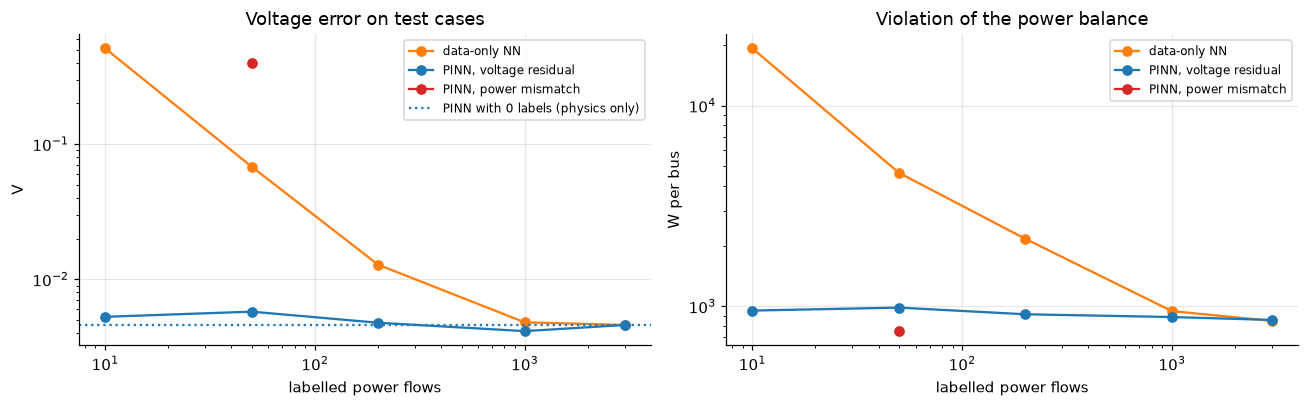

In [5]:
x_train, v_train = to_x(S_all[:3000]), to_v(V_all[:3000])
V_te, S_te = V_all[3000:], S_all[3000:]
rows, t0 = [], time.perf_counter()
for n_lab in (0, 10, 50, 200, 1000, 3000):
    xl, vl = x_train[:n_lab], v_train[:n_lab]
    if n_lab > 0:
        rows.append({"labelled power flows": n_lab, "model": "data-only NN", **evaluate(train(xl, vl), V_te, S_te)})
    rows.append({"labelled power flows": n_lab, "model": "PINN, voltage residual", **evaluate(train(xl, vl, x_phys=x_train), V_te, S_te)})
    if n_lab in (0, 50):
        m = train(xl, vl, x_phys=x_train, physics=residual_power)
        rows.append({"labelled power flows": n_lab, "model": "PINN, power mismatch", **evaluate(m, V_te, S_te)})
print(f"{len(rows)} models trained in {time.perf_counter() - t0:.0f} s")
res = pd.DataFrame(rows)
display(res.pivot(index="labelled power flows", columns="model", values="voltage MAE [V]").round(3).add_suffix("  · MAE [V]"))
display(res.set_index(["labelled power flows", "model"]).round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for mdl, c_ in (("data-only NN", "tab:orange"), ("PINN, voltage residual", "tab:blue"), ("PINN, power mismatch", "tab:red")):
    r = res[(res.model == mdl) & (res["labelled power flows"] > 0)]
    ax[0].plot(r["labelled power flows"], r["voltage MAE [V]"], "o-", color=c_, label=mdl)
    ax[1].plot(r["labelled power flows"], r["power mismatch mean [W]"], "o-", color=c_, label=mdl)
p0 = res[(res["labelled power flows"] == 0) & (res.model == "PINN, voltage residual")].iloc[0]
ax[0].axhline(p0["voltage MAE [V]"], color="tab:blue", ls=":", label="PINN with 0 labels (physics only)")
ax[0].set(xscale="log", yscale="log", xlabel="labelled power flows", ylabel="V", title="Voltage error on test cases"); ax[0].legend(fontsize=8)
ax[1].set(xscale="log", yscale="log", xlabel="labelled power flows", ylabel="W per bus", title="Violation of the power balance"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Reading the results**
* With **zero labels**, the voltage-residual PINN already predicts voltages to ~0.005 V, as accurately as a data-only
  network trained on 1 000 solved power flows. The physics alone is enough to learn the power flow.
* The power-mismatch PINN reaches the *smallest* ΔP/ΔQ, yet has the *largest* voltage errors: its loss is small in the
  stiff directions and blind to common-mode voltage errors, i.e. the conditioning problem of section 2 in action.
* For the same reason ΔP/ΔQ is a poor accuracy measure in stiff grids: hundreds of watts of mismatch per bus
  correspond to voltage errors of a few millivolts.

## 5. A new scenario without a single new simulation
The planner asks: *what if all PV capacity triples?* The PINN can be trained on the **injections** of the new
scenario (physics term only, no power flows); a data-only network cannot use them.

In [6]:
x_new = to_x(S_pv3)
m_data = train(x_train, v_train)
m_pinn = train(x_train, v_train, x_phys=x_train)
m_pinn_new = train(x_train, v_train, x_phys=torch.cat([x_train, x_new]))
rows2 = [{"model": "data-only NN (today's PV, 3 000 labels)", **evaluate(m_data, V_pv3, S_pv3)},
         {"model": "PINN (today's PV)", **evaluate(m_pinn, V_pv3, S_pv3)},
         {"model": "PINN + unlabelled PV×3 injections", **evaluate(m_pinn_new, V_pv3, S_pv3)}]
display(pd.DataFrame(rows2).set_index("model").round(3))
print(f"highest voltage: today {np.abs(V_all[:, pq]).max():.3f} pu | with PV×3 {np.abs(V_pv3[:, pq]).max():.3f} pu")

,voltage MAE [V],voltage max error [V],power mismatch mean [W]
model,,,
"data-only NN (today's PV, 3 000 labels)",0.071,7.608,3228.733887
PINN (today's PV),0.071,7.561,3153.581055
PINN + unlabelled PV×3 injections,0.009,0.423,1620.759033


highest voltage: today 1.039 pu | with PV×3 1.078 pu


Trained only on today's injections, both networks are equally lost in the PV×3 world (voltages up to 1.08 pu, never
seen). Adding the **unlabelled** PV×3 injections to the physics term cuts the error about eightfold without a single
new power flow.

## Key takeaways
* The physics term turns every *unsolved* scenario into training data: it constrains the network wherever we know
  the injections, not only where we ran the solver.
* **How the physics is written matters as much as including it.** The textbook ΔP/ΔQ mismatch is badly conditioned
  for low-impedance distribution grids; the same physics written as a voltage residual (Z-bus fixed point) trains
  well. Check the conditioning of a physics loss before blaming the network.
* PINNs shine where labels are scarce or the scenario is new; with thousands of solved cases from the same
  distribution, a plain network is hard to beat.
* Costs: the physics must be implemented differentiably, training is slower, and the weight $\lambda$ needs tuning.